# Machine learning pipeline
- using a toy dataset from scyikit_learn

In [ ]:
from sklearn.datasets import make_moons
import numpy as np
import matplotlib.pyplot as plt

RANDOM_SEED = 42
X,y = make_moons(n_samples=900,noise=0.25,random_state=RANDOM_SEED)

- shape of the dataset 

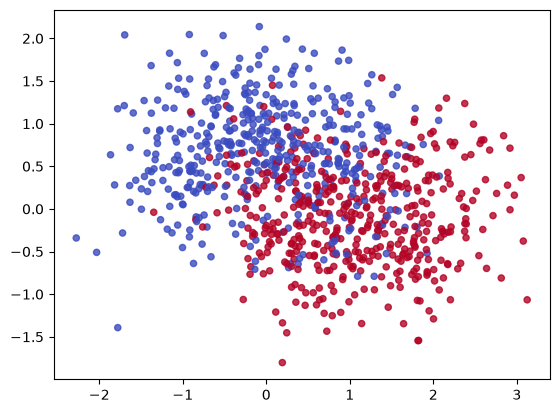

In [5]:
plt.scatter(X[:,0],X[:,1],c=y,cmap="coolwarm",s=20,alpha=0.8)
plt.show()

# Data preprocessing
Could be for missing values or other reason.

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_other, y_train, y_other = train_test_split(X,y,test_size=0.4,shuffle=True,stratify=y,random_state=RANDOM_SEED)

In [16]:
X_train.shape,X_other.shape

((540, 2), (360, 2))

In [17]:

X_val, X_test, y_val, y_test = train_test_split(X,y,test_size=0.5,shuffle=True,stratify=y,random_state=RANDOM_SEED)

Train a new model and plot the decision boundaries  

In [46]:
def decision_boundary(ax,estimator,xx,yy,title):
    low = X.min(axis=0) - 0.5
    high = X.max(axis=0) + 0.5

    gx,gy = np.meshgrid(
        np.linspace(low[0],high[0],150),
        np.linspace(low[1],high[1],150),
    )
    zz = estimator.predict(np.c_[gx.ravel(),gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx,gy,zz,alpha=0.3,cmap="coolwarm",levels=[-.5,.5,1.5])
    ax.contour(gx,gy,zz,levels=[.5],colors="black",linewidth=1)
    ax.scatter(xx[:,0],xx[:,1],c=yy,cmap="coolwarm",s=9,alpha=0.8)
    ax.set_title(title,fontsize=10)
    ax.grid(alpha=0.1)

dictionary with different type of models

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler 
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    "LR (L1)": make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l1",solver="liblinear",C=0.1,max_iter=1000,random_state=RANDOM_SEED)),
    "LR (L2)": make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l2",solver="liblinear",C=0.1,max_iter=1000,random_state=RANDOM_SEED)),
     "SVM (MBP)": make_pipeline(
        StandardScaler(),
         SVC(kernel="rbf",C=1.0)),
      "SVM (Poly)": make_pipeline(
        StandardScaler(),
         SVC(kernel="poly",C=1.0)),
    "DT": make_pipeline(DecisionTreeClassifier(max_depth=5,random_state=RANDOM_SEED)),
    "MB": GaussianNB(),
    "AdaBoost": AdaBoostClassifier(n_estimators=100,learning_rate=0.5,random_state=RANDOM_SEED),
    "RF": RandomForestClassifier(n_estimators=100,max_depth=5,random_state=RANDOM_SEED),
    "kNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}


Training models, .fit() is the function to do it

/home/francesco/miniforge3/envs/mldl/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/francesco/miniforge3/envs/mldl/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/francesco/miniforge3/envs/mldl/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio

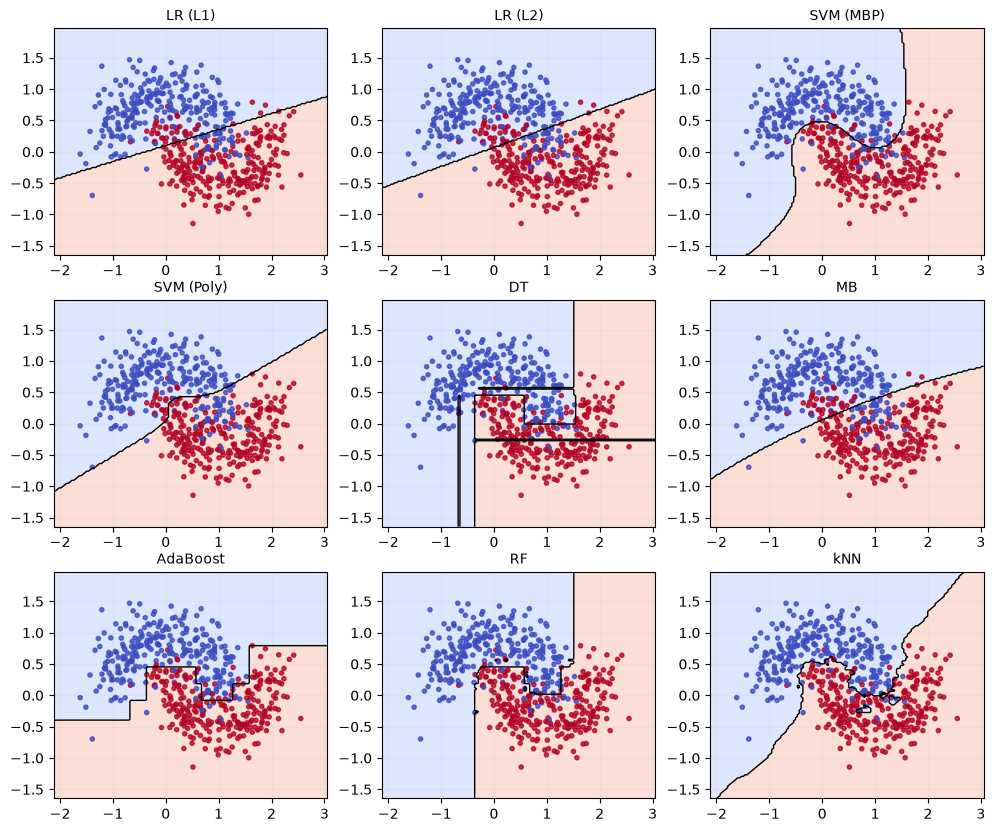

In [48]:
for model in models.values():
    model.fit(X_train,y_train)

fig, axes = plt.subplots(3,3,figsize=(12,10))
for ax,(name,model) in zip(axes.ravel(),models.items()):
    decision_boundary(ax,model,X_train,y_train,name)
plt.show()


Gridsearch for only a method (as excercise try to do it with all method)

In [56]:
from sklearn.model_selection import GridSearchCV,StratifiedKFold
model = make_pipeline(StandardScaler(),SVC(kernel="rbf"))
param_grid = {
    "svc__C": [.1,1,10],
    "svc__gamma": ["scale",.1,1]
}

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_SEED)
X_dev = np.concatenate([X_train,X_val])
y_dev = np.concatenate([y_train,y_val])

grid = GridSearchCV(model,param_grid=param_grid,scoring="accuracy",refit=True)
grid.fit(X_dev,y_dev)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svc', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svc__C': [0.1, 1, ...], 'svc__gamma': ['scale', 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of

In [58]:
final_model = grid.best_estimator_

In [60]:
from sklearn.metrics import accuracy_score
y_pred = final_model.predict(X_test) 
print(accuracy_score(y_test,y_pred))

0.9422222222222222
